# MsPacMan · Forbedringsforsøk i B

Fire varianter bruker samme miljø, frø, poengbonus og treningsbudsjett. Q-table er kontrollen for Q-table-pellet, som legger én pelletretning til tilstanden. PPO med 2,5e-4 er kontrollen for PPO-low-lr med 1,25e-4. Resultater for kontroll og variant sammenlignes per treningsfrø.

Standardbudsjettet er 65 536 interaksjoner per agent. Sett ALGORITHMS til de variantene du vil kjøre. Q-table alene er den korteste måten å teste økt budsjett. Alle fire med de tre standardfrøene gir 12 agenter. Du kan også sette TRAIN_BUDGET til 32_768 for en kortere kjøring.

Begge metoder får den samme bonusen for økning i spillscore og +1 ved 2 000 poeng. Q-tabellen velger grådig ved evaluering, og PPO sampler handlinger.

Pelletsignalet bruker retningen langs en tilnærmet korteste rute til en gjenværende vanlig pellet. Labyrintens korridorer avledes fra et oppstartsbilde, og gjenværende pellets leses fra Atari-RAM. Dette signalet gjelder originalkartet i B. Retningen legges til de eksisterende tilstandsvariablene. [OCAtaris RAM-kilde](https://github.com/k4ntz/OC_Atari/blob/master/ocatari/ram/mspacman.py#L237-L286)

Lagre og mål hver 8 192. interaksjon med 24 monitoreringsfrø. Sluttevaluering bruker 200 separate frø per agent. Velg eventuelt et tidligere, lagret målepunkt i siste celle. Velg det ut fra monitoreringskurven for å unngå å velge på bakgrunn av sluttesten. Kontrollens 32 768-målepunkt kan evalueres på samme frø som den frosne 65 536-modellen.

Åpne notebooken med Python 3.12 fra oppgavemappen. Evaluerte kjøringer dukker opp i dashboardet med modeller, CSV-er og gameplay.

In [1]:
%pip install "gymnasium[atari]==1.2.3" "ale-py==0.11.2" "opencv-python-headless>=4.10,<5" "pandas>=2.2,<3" "matplotlib>=3.9,<4" "joblib>=1.4,<2" "torch==2.7.1"

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from dataclasses import asdict, dataclass
from datetime import datetime, timezone
from functools import partial
from importlib.metadata import version
from pathlib import Path
from shutil import copy2
from time import perf_counter
import gzip
import json
import os
import platform

import ale_py
import gymnasium as gym
from gymnasium.wrappers import FrameStackObservation, RecordEpisodeStatistics, ResizeObservation, TimeLimit
from IPython.display import display
from joblib import Parallel, delayed, parallel_config
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from torch.distributions import Categorical

from mspacman_pellets import PelletGuide

gym.register_envs(ale_py)


ENV_ID = "ALE/MsPacman-v5"
SUCCESS_POINTS = 2_000
MAX_EPISODE_STEPS = 1_024
FRAME_SKIP = 4
OBS_SHAPE = (4, 42, 42)
TRAINING_SEEDS = (42, 43, 44)
MONITOR_SEEDS = tuple(range(100_000, 100_024))
TEST_SEEDS = tuple(range(200_000, 200_200))
CHECKPOINT_EVERY = 8_192
TRAIN_BUDGET = 65_536
TRAIN_ENVS = 8
EVAL_ENVS = 24
EVAL_WORKERS = min(4, os.cpu_count() or 1)
SCORE_BONUS = 0.25
GAMMA = 0.99
Q_TABLE = dict(alpha=0.15, epsilon_start=1.0, epsilon_end=0.10,
               exploration_steps=12_288, position_bin=12, ghost_radius=24)
PPO = dict(lr=2.5e-4, rollout_steps=64, gae_lambda=0.95, clip=0.20,
           epochs=4, batch_size=64, entropy_coef=0.01, value_coef=0.5,
           max_grad_norm=0.5)
ALGORITHMS = ("Q-table", "Q-table-pellet", "PPO", "PPO-low-lr")
SETTING = "B"
PARAMS = {"Q-table": Q_TABLE, "Q-table-pellet": dict(Q_TABLE, pellet_direction=True),
          "PPO": PPO, "PPO-low-lr": dict(PPO, lr=1.25e-4)}
TABULAR_ALGORITHMS = {"Q-table", "Q-table-pellet"}
POLICIES = {name: ("greedy Q-table (current direction on ties when available)"
                   if name in TABULAR_ALGORITHMS else "sampled categorical") for name in PARAMS}
DEVICE = torch.device("cpu")
TORCH_THREADS = 1
torch.set_num_threads(TORCH_THREADS)


@dataclass(frozen=True)
class Setting:
    sticky: float
    step_penalty: float = 0.0
    maze: int = 0
    score_bonus: float = 0.0


SETTINGS = {SETTING: Setting(sticky=0.25, score_bonus=SCORE_BONUS)}
assert np.isfinite(SCORE_BONUS) and SCORE_BONUS > 0
assert ALGORITHMS and len(ALGORITHMS) == len(set(ALGORITHMS)) and set(ALGORITHMS) <= PARAMS.keys()
assert TRAIN_BUDGET > 0 and TRAIN_BUDGET % CHECKPOINT_EVERY == 0
assert CHECKPOINT_EVERY % (TRAIN_ENVS * PPO["rollout_steps"]) == 0
assert set(MONITOR_SEEDS).isdisjoint(TEST_SEEDS)

In [3]:
class MazeStart(gym.Wrapper):
    """Select the ROM's starting maze before the initial frame is stacked."""

    def __init__(self, env, maze):
        super().__init__(env)
        self.maze = maze
        self.ale = self.unwrapped.ale
        self.noop = self.unwrapped.get_action_meanings().index("NOOP")

    def reset(self, *, seed=None, options=None):
        self.env.reset(seed=seed, options=options)
        if self.maze != 0:
            self.ale.setRAM(0, self.maze)
        observation, points, terminated, truncated, info = self.env.step(self.noop)
        if points != 0 or terminated or truncated or self.ale.getRAM()[0] != self.maze:
            raise RuntimeError("Unexpected MsPacman state during maze reset.")
        return observation, info


class ScoreGoal(gym.Wrapper):
    def __init__(self, env, setting):
        super().__init__(env)
        self.setting = setting
        self.ale = self.unwrapped.ale

    def reset(self, **kwargs):
        self.score = 0.0
        return self.env.reset(**kwargs)

    def step(self, action):
        obs, points, game_over, timeout, info = self.env.step(action)
        self.score += float(points)
        success = self.score >= SUCCESS_POINTS
        maze_exit = int(self.ale.getRAM()[0]) != self.setting.maze
        terminated = bool(success or game_over or maze_exit)
        truncated = bool(timeout and not terminated)
        outcome = ("success" if success else "game_over" if game_over else
                   "maze_exit" if maze_exit else "timeout" if truncated else "in_progress")
        reward = (float(success) + self.setting.score_bonus * float(points) / SUCCESS_POINTS
                  - self.setting.step_penalty)
        info.update(raw_points=float(points), raw_score=self.score, outcome=outcome)
        return obs, reward, terminated, truncated, info


def tabular_state(ram):
    """Encode coarse player position, heading and the nearest nearby ghost."""
    x, y = int(ram[10]), int(ram[16])
    heading = int(ram[56]) & 3
    sector = 9
    if ram[47] > 0:
        ghosts = range(1 + min(int(ram[19]), 3))
        offsets = [(int(ram[6 + i]) - x, int(ram[12 + i]) - y) for i in ghosts]
        dx, dy = min(offsets, key=lambda offset: abs(offset[0]) + abs(offset[1]))
        if abs(dx) + abs(dy) <= Q_TABLE["ghost_radius"]:
            sx = int(dx > 0) - int(dx < 0)
            sy = int(dy > 0) - int(dy < 0)
            sector = (sx + 1) * 3 + sy + 1
    position_bin = Q_TABLE["position_bin"]
    return x // position_bin, y // position_bin, heading, sector


class TabularObservation(gym.ObservationWrapper):
    def __init__(self, env, pellet_guide=None):
        super().__init__(env)
        self.pellet_guide = pellet_guide
        positions = 255 // Q_TABLE["position_bin"] + 1
        bins = [positions, positions, 4, 10]
        if pellet_guide is not None:
            bins.append(5)
        self.observation_space = gym.spaces.MultiDiscrete(bins)

    def observation(self, observation):
        ram = self.unwrapped.ale.getRAM()
        state = tabular_state(ram)
        if self.pellet_guide is not None:
            state += (self.pellet_guide.direction(ram),)
        return np.asarray(state, dtype=np.int64)


def build_environment(setting_name, algorithm=None):
    setting = SETTINGS[setting_name]
    env = gym.make(ENV_ID, obs_type="grayscale", frameskip=FRAME_SKIP,
                   repeat_action_probability=setting.sticky, full_action_space=False)
    env = MazeStart(env, setting.maze)
    env = ResizeObservation(env, OBS_SHAPE[1:])
    env = FrameStackObservation(env, stack_size=OBS_SHAPE[0])
    env = TimeLimit(env, max_episode_steps=MAX_EPISODE_STEPS)
    env = RecordEpisodeStatistics(ScoreGoal(env, setting))
    if algorithm in TABULAR_ALGORITHMS:
        guide = PELLET_GUIDE if algorithm == "Q-table-pellet" else None
        return TabularObservation(env, guide)
    return env


PELLET_GUIDE = None
if "Q-table-pellet" in ALGORITHMS:
    with build_environment(SETTING) as probe:
        probe.reset(seed=900_001)
        PELLET_GUIDE = PelletGuide(probe.unwrapped.ale.getScreenRGB())

for algorithm in ALGORITHMS:
    with build_environment(SETTING, algorithm) as probe:
        initial, _ = probe.reset(seed=900_001)
        assert probe.observation_space.contains(initial)
        ACTION_NAMES = probe.unwrapped.get_action_meanings()
        assert [ACTION_NAMES[i] for i in (1, 2, 4, 3)] == ["UP", "RIGHT", "DOWN", "LEFT"]

In [4]:
class TrainingBatch:
    def __init__(self, setting, seed, algorithm):
        self.env = gym.vector.SyncVectorEnv(
            [partial(build_environment, setting, algorithm) for _ in range(TRAIN_ENVS)],
            autoreset_mode=gym.vector.AutoresetMode.DISABLED,
        )
        env_seeds = [seed * 1_000 + i for i in range(TRAIN_ENVS)]
        self.obs, _ = self.env.reset(seed=env_seeds)
        self.actions = self.env.single_action_space.n
        self.interactions = 0
        self.episodes = []

    def step(self, actions):
        next_obs, rewards, terminated, truncated, info = self.env.step(actions)
        self.interactions += TRAIN_ENVS
        done = terminated | truncated
        for i in np.flatnonzero(done):
            self.episodes.append(dict(interactions=self.interactions, env_index=int(i),
                                      episode_return=float(info["episode"]["r"][i]),
                                      length=int(info["episode"]["l"][i]),
                                      raw_score=float(info["raw_score"][i]),
                                      outcome=str(info["outcome"][i])))
        if done.any():
            self.obs, _ = self.env.reset(options={"reset_mask": done})
        else:
            self.obs = next_obs
        return next_obs, rewards, terminated, done


class TabularQModel:
    def __init__(self, action_count, state_size):
        self.state_size = state_size
        self.zero = np.zeros(action_count, dtype=np.float64)
        self.q = {}

    def values(self, state):
        return self.q.get(tuple(state), self.zero)

    def greedy(self, state):
        values = self.values(state)
        best = int(values.argmax())
        forward = (1, 2, 4, 3)[state[2]]  # UP, RIGHT, DOWN, LEFT in the ALE minimal action space.
        return forward if values[forward] == values[best] else best

    def save(self, path):
        keys = np.asarray(list(self.q), dtype=np.int16).reshape(-1, self.state_size)
        values = np.asarray(list(self.q.values()), dtype=np.float64).reshape(-1, len(self.zero))
        np.savez_compressed(path, keys=keys, values=values)


class TabularQTrainer:
    def __init__(self, action_count, seed, algorithm):
        self.model = TabularQModel(action_count, 5 if algorithm == "Q-table-pellet" else 4)
        self.rng = np.random.default_rng(seed)
        self.updates = 0

    def train_until(self, batch, stop):
        cfg = Q_TABLE
        while batch.interactions < stop:
            observations = batch.obs
            epsilon = np.interp(batch.interactions, [0, cfg["exploration_steps"]],
                                [cfg["epsilon_start"], cfg["epsilon_end"]])
            actions = np.array([self.rng.integers(batch.actions) if self.rng.random() < epsilon
                                else self.model.greedy(state) for state in observations])
            next_obs, rewards, terminated, _ = batch.step(actions)
            for state, action, reward, next_state, terminal in zip(observations, actions, rewards, next_obs, terminated):
                key = tuple(state)
                if key not in self.model.q:
                    self.model.q[key] = self.model.zero.copy()
                values = self.model.q[key]
                future = 0.0 if terminal else self.model.values(next_state).max()
                values[action] += cfg["alpha"] * (reward + GAMMA * future - values[action])
                self.updates += 1


class AtariEncoder(nn.Sequential):
    def __init__(self):
        super().__init__(nn.Conv2d(4, 16, 6, stride=4), nn.ReLU(),
                         nn.Conv2d(16, 32, 4, stride=2), nn.ReLU(), nn.Flatten(),
                         nn.Linear(32 * 4 * 4, 128), nn.ReLU())

    def forward(self, pixels):
        return super().forward(pixels.float() / 255.0)



class AtariActorCritic(nn.Module):
    def __init__(self, action_count):
        super().__init__()
        self.encoder = AtariEncoder()
        self.actor = nn.Linear(128, action_count)
        self.critic = nn.Linear(128, 1)
        nn.init.orthogonal_(self.actor.weight, gain=0.01)
        nn.init.zeros_(self.actor.bias)
        nn.init.orthogonal_(self.critic.weight)
        nn.init.zeros_(self.critic.bias)

    def forward(self, pixels):
        features = self.encoder(pixels)
        return self.actor(features), self.critic(features).squeeze(-1)


def tensor(array):
    return torch.as_tensor(array, device=DEVICE)



def gae_targets(rewards, values, next_values, terminated, done):
    """Bootstrap at time limits, but stop GAE at any episode boundary."""
    advantages = torch.empty_like(values)
    gae = torch.zeros_like(values[0])
    for t in range(len(values) - 1, -1, -1):
        delta = rewards[t] + GAMMA * (~terminated[t]) * next_values[t] - values[t]
        gae = delta + GAMMA * PPO["gae_lambda"] * (~done[t]) * gae
        advantages[t] = gae
    return advantages, advantages + values


class PPOTrainer:
    def __init__(self, action_count, seed, algorithm):
        self.rng = np.random.default_rng(seed)
        self.action_rng = torch.Generator(device=DEVICE).manual_seed(seed)
        with torch.random.fork_rng(devices=[]):
            torch.manual_seed(seed)
            self.model = AtariActorCritic(action_count).to(DEVICE)
        self.optimizer = torch.optim.Adam(self.model.parameters(), lr=PARAMS[algorithm]["lr"], eps=1e-5)
        self.updates = 0

    @torch.no_grad()
    def collect(self, batch):
        rollout = []
        for _ in range(PPO["rollout_steps"]):
            states = tensor(batch.obs)
            logits, values = self.model(states)
            distribution = Categorical(logits=logits)
            actions = torch.multinomial(distribution.probs, 1, replacement=True, generator=self.action_rng).squeeze(-1)
            next_obs, rewards, terminated, done = batch.step(actions.cpu().numpy())
            _, next_values = self.model(tensor(next_obs))
            rollout.append((states, actions, distribution.log_prob(actions), values,
                            next_values, tensor(rewards.astype(np.float32)),
                            tensor(terminated), tensor(done)))
        states, actions, logp, values, next_values, rewards, term, done = map(torch.stack, zip(*rollout))
        advantages, targets = gae_targets(rewards, values, next_values, term, done)
        advantages = (advantages - advantages.mean()) / (advantages.std(unbiased=False) + 1e-8)
        return tuple(x.flatten(0, 1) for x in (states, actions, logp, advantages, targets))

    def train_until(self, batch, stop):
        self.model.train()
        while batch.interactions < stop:
            states, actions, old_logp, advantages, targets = self.collect(batch)
            for _ in range(PPO["epochs"]):
                for indices in np.split(self.rng.permutation(len(actions)), len(actions) // PPO["batch_size"]):
                    logits, values = self.model(states[indices])
                    policy = Categorical(logits=logits)
                    ratio = (policy.log_prob(actions[indices]) - old_logp[indices]).exp()
                    adv = advantages[indices]
                    clipped = ratio.clamp(1 - PPO["clip"], 1 + PPO["clip"])
                    actor_loss = -torch.minimum(ratio * adv, clipped * adv).mean()
                    value_loss = F.mse_loss(values, targets[indices])
                    loss = actor_loss + PPO["value_coef"] * value_loss - PPO["entropy_coef"] * policy.entropy().mean()
                    self.optimizer.zero_grad(set_to_none=True)
                    loss.backward()
                    nn.utils.clip_grad_norm_(self.model.parameters(), PPO["max_grad_norm"])
                    self.optimizer.step()
                    self.updates += 1

In [5]:
@torch.inference_mode()
def evaluate(model, algorithm, setting, seeds, record_actions=False):
    if algorithm not in TABULAR_ALGORITHMS:
        model.eval()
    results, traces = [], []
    start = perf_counter()
    envs = [build_environment(setting, algorithm) for _ in range(min(EVAL_ENVS, len(seeds)))]
    try:
        # Separate generators keep PPO's actions reproducible across batch sizes.
        uniforms = [np.random.default_rng([seed, 29]).random(MAX_EPISODE_STEPS) for seed in seeds]
        for offset in range(0, len(seeds), len(envs)):
            batch_seeds = seeds[offset:offset + len(envs)]
            ob = {i: envs[i].reset(seed=seed)[0] for i, seed in enumerate(batch_seeds)}
            action_logs = [[] for _ in batch_seeds]
            seen = np.zeros(len(batch_seeds), dtype=int)
            for step in range(MAX_EPISODE_STEPS):
                if not ob:
                    break
                slots = list(ob)
                if algorithm in TABULAR_ALGORITHMS:
                    actions = [model.greedy(ob[i]) for i in slots]
                    for i in slots:
                        seen[i] += tuple(ob[i]) in model.q
                else:
                    logits, _ = model(tensor(np.stack(list(ob.values()))))
                    cdf = logits.softmax(dim=1).cumsum(dim=1).numpy()
                    cdf[:, -1] = 1.0
                    draws = [uniforms[offset + i][step] for i in slots]
                    actions = (np.asarray(draws)[:, None] >= cdf).sum(axis=1)
                for i, action in zip(slots, actions):
                    ob[i], _, terminated, truncated, info = envs[i].step(int(action))
                    if record_actions:
                        action_logs[i].append(int(action))
                    if terminated or truncated:
                        seed = batch_seeds[i]
                        results.append(dict(eval_seed=seed, length=int(info["episode"]["l"]),
                                            episode_return=float(info["episode"]["r"]),
                                            raw_score=float(info["raw_score"]), outcome=info["outcome"]))
                        if algorithm in TABULAR_ALGORITHMS:
                            results[-1]["known_state_steps"] = int(seen[i])
                        if record_actions:
                            traces.append(dict(eval_seed=seed, actions=action_logs[i]))
                        del ob[i]
            assert not ob, "Gymnasium TimeLimit should end every episode in the batch."
    finally:
        for env in envs:
            env.close()
    return sorted(results, key=lambda row: row["eval_seed"]), traces, perf_counter() - start


def load_model(algorithm, path):
    if algorithm in TABULAR_ALGORITHMS:
        model = TabularQModel(len(ACTION_NAMES), 5 if algorithm == "Q-table-pellet" else 4)
        with np.load(path, allow_pickle=False) as checkpoint:
            model.q = {tuple(key): values.copy() for key, values in
                       zip(checkpoint["keys"], checkpoint["values"], strict=True)}
        return model
    model = AtariActorCritic(len(ACTION_NAMES)).to(DEVICE)
    model.load_state_dict(torch.load(path, map_location=DEVICE, weights_only=True))
    return model.eval()


def summarize(episodes):
    success = [row["length"] for row in episodes if row["outcome"] == "success"]
    failure = [row["length"] for row in episodes if row["outcome"] != "success"]
    coverage = {}
    if "known_state_steps" in episodes[0]:
        coverage["known_state_rate"] = sum(row["known_state_steps"] for row in episodes) / sum(
            row["length"] for row in episodes)
    above_1000 = sum(row["raw_score"] >= 1_000 for row in episodes)
    return dict(**coverage, episodes=len(episodes), successes=len(success), failures=len(failure),
                score_1000_episodes=above_1000, score_1000_rate=above_1000 / len(episodes),
                success_rate=len(success) / len(episodes), failure_rate=len(failure) / len(episodes),
                mean_return=float(np.mean([row["episode_return"] for row in episodes])),
                mean_raw_score=float(np.mean([row["raw_score"] for row in episodes])),
                success_length=float(np.mean(success)) if success else np.nan,
                failure_length=float(np.mean(failure)) if failure else np.nan,
                eval_interactions=sum(row["length"] for row in episodes))



def run_test(run, setting, output):
    torch.set_num_threads(TORCH_THREADS)
    gym.register_envs(ale_py)
    algorithm = run["algorithm"]
    eval_id = f"{run['run_id']}__eval-{setting}"
    model = load_model(algorithm, output / run["checkpoint"])
    rows, traces, elapsed = evaluate(model, algorithm, setting, TEST_SEEDS, record_actions=True)
    folder = output / run["run_id"]
    pd.DataFrame(rows).assign(eval_id=eval_id).to_csv(folder / f"evaluation_{setting}.csv", index=False)
    with gzip.open(folder / f"actions_{setting}.jsonl.gz", "wt", encoding="utf-8") as stream:
        for trace in sorted(traces, key=lambda row: row["eval_seed"]):
            stream.write(json.dumps(trace, separators=(",", ":")) + "\n")
    print(f"{eval_id}: {len(rows)} held-out episodes in {elapsed:.1f} s", flush=True)
    return dict(eval_id=eval_id, setting=setting, policy=POLICIES[algorithm], eval_seconds=elapsed,
                **run, **summarize(rows))

In [6]:
def cpu_name():
    if platform.system() == "Windows":
        import winreg
        with winreg.OpenKey(winreg.HKEY_LOCAL_MACHINE, r"HARDWARE\DESCRIPTION\System\CentralProcessor\0") as key:
            return winreg.QueryValueEx(key, "ProcessorNameString")[0].strip()
    if Path("/proc/cpuinfo").exists():
        for line in Path("/proc/cpuinfo").read_text().splitlines():
            if line.startswith("model name"):
                return line.split(":", 1)[1].strip()
    return platform.processor() or platform.machine()


def experiment_settings(budget):
    return dict(env_id=ENV_ID, success_points=SUCCESS_POINTS, max_episode_steps=MAX_EPISODE_STEPS,
                observation_shape=OBS_SHAPE, action_names=ACTION_NAMES, frame_skip=FRAME_SKIP,
                settings={SETTING: asdict(SETTINGS[SETTING])}, training_seeds=TRAINING_SEEDS,
                monitor_seeds=MONITOR_SEEDS, test_seeds=TEST_SEEDS, interaction_budget=budget,
                checkpoint_every=CHECKPOINT_EVERY, gamma=GAMMA, algorithms={name: PARAMS[name] for name in ALGORITHMS},
                eval_modes={name: POLICIES[name] for name in ALGORITHMS},
                hardware=dict(device="cpu", cpu=cpu_name(), logical_cpus=os.cpu_count(),
                              training_envs=TRAIN_ENVS, evaluation_batch_size=EVAL_ENVS,
                              evaluation_workers=EVAL_WORKERS),
                software={name: version(name) for name in ("gymnasium", "ale-py", "numpy", "torch",
                          "opencv-python-headless", "pandas", "matplotlib", "joblib")},
                python=platform.python_version(), operating_system=platform.platform())


def create_output(budget, source=None):
    label = f"Forbedringsforsøk · {budget:,}".replace(",", " ")
    output = Path("part2_results") / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
    output.mkdir(parents=True)
    manifest = dict(experiment_settings(budget), label=label)
    if source is not None:
        manifest["source_run"] = source.name
    (output / "experiment.json").write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8")
    return output


def save_checkpoint(trainer, algorithm, folder, target):
    suffix = ".npz" if algorithm in TABULAR_ALGORITHMS else ".pt"
    path = folder / "checkpoints" / f"{target}{suffix}"
    if algorithm in TABULAR_ALGORITHMS:
        trainer.model.save(path)
    else:
        torch.save(trainer.model.state_dict(), path)
    return path


def train_agent(algorithm, seed, budget, output):
    run_id = f"{SETTING}-{algorithm}-s{seed}"
    folder = output / run_id
    (folder / "checkpoints").mkdir(parents=True)
    batch = TrainingBatch(SETTING, seed, algorithm)
    trainer_class = TabularQTrainer if algorithm in TABULAR_ALGORITHMS else PPOTrainer
    training_seconds = 0.0
    curve, monitor_rows, checkpoints = [], [], []
    try:
        trainer = trainer_class(batch.actions, seed, algorithm)
        for target in range(0, budget + 1, CHECKPOINT_EVERY):
            if target:
                start = perf_counter()
                trainer.train_until(batch, target)
                training_seconds += perf_counter() - start
            assert batch.interactions == target
            path = save_checkpoint(trainer, algorithm, folder, target)
            config = dict(run_id=run_id, train_setting=SETTING, algorithm=algorithm, train_seed=seed,
                          training_interactions=target, training_seconds=training_seconds,
                          optimizer_updates=trainer.updates, completed_training_episodes=len(batch.episodes),
                          params=PARAMS[algorithm], env_seeds=[seed * 1_000 + i for i in range(TRAIN_ENVS)],
                          checkpoint=path.relative_to(output).as_posix())
            if algorithm in TABULAR_ALGORITHMS:
                config["q_table_states"] = len(trainer.model.q)
            checkpoints.append(config)
            (folder / "checkpoints.json").write_text(json.dumps(checkpoints, indent=2), encoding="utf-8")
            rows, _, elapsed = evaluate(trainer.model, algorithm, SETTING, MONITOR_SEEDS)
            monitor_rows.extend(dict(row, run_id=run_id, interactions=target) for row in rows)
            record = dict(run_id=run_id, setting=SETTING, algorithm=algorithm, train_seed=seed,
                          interactions=target, training_seconds=training_seconds, monitor_seconds=elapsed,
                          **summarize(rows))
            curve.append(record)
            print(f"{run_id}: {target:,} interactions, monitor score {record['mean_raw_score']:.1f}", flush=True)
        (folder / "run.json").write_text(json.dumps(checkpoints[-1], indent=2), encoding="utf-8")
        pd.DataFrame(monitor_rows).to_csv(folder / "monitor_episodes.csv", index=False)
        pd.DataFrame(batch.episodes).assign(run_id=run_id).to_csv(folder / "training_episodes.csv", index=False)
        return checkpoints[-1], curve
    finally:
        batch.env.close()


def train_experiment(budget):
    output = create_output(budget)
    runs, curves = [], []
    for seed in TRAINING_SEEDS:
        for algorithm in ALGORITHMS:
            run, records = train_agent(algorithm, seed, budget, output)
            runs.append(run)
            curves.extend(records)
    learning = pd.DataFrame(curves)
    learning.to_csv(output / "learning_curves.csv", index=False)
    print(output)
    return dict(output=output, budget=budget, runs=runs, learning=learning)


def earlier_stage(full_stage, budget):
    if budget == full_stage["budget"]:
        return full_stage
    if not 0 <= budget < full_stage["budget"] or budget % CHECKPOINT_EVERY:
        raise ValueError("Choose an existing saved checkpoint from the learning curve.")
    source = full_stage["output"]
    selections = []
    for run in full_stage["runs"]:
        before = source / run["run_id"]
        manifest = json.loads((before / "checkpoints.json").read_text(encoding="utf-8"))
        config = next(row for row in manifest if row["training_interactions"] == budget)
        selections.append((before, config))
    output = create_output(budget, source=source)
    for before, config in selections:
        after = output / config["run_id"]
        (output / config["checkpoint"]).parent.mkdir(parents=True)
        copy2(source / config["checkpoint"], output / config["checkpoint"])
        for name in ("training_episodes.csv", "monitor_episodes.csv"):
            rows = pd.read_csv(before / name)
            rows.loc[rows["interactions"] <= budget].to_csv(after / name, index=False)
        (after / "run.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
    learning = full_stage["learning"].query("interactions <= @budget").copy()
    learning.to_csv(output / "learning_curves.csv", index=False)
    return dict(output=output, budget=budget, runs=[config for _, config in selections], learning=learning)

In [7]:
def evaluate_stage(stage):
    output = stage["output"]
    completed = output / "per_agent.csv"
    if completed.is_file():
        return pd.read_csv(completed)
    with parallel_config(backend="loky", inner_max_num_threads=1):
        test_rows = Parallel(n_jobs=EVAL_WORKERS, verbose=5, max_nbytes=None)(
            delayed(run_test)(run, SETTING, output) for run in stage["runs"]
        )
    per_agent = pd.DataFrame(test_rows).sort_values(["algorithm", "train_seed"])
    assert len(per_agent) == len(ALGORITHMS) * len(TRAINING_SEEDS)
    assert (per_agent["training_interactions"] == stage["budget"]).all()
    assert (per_agent["episodes"] == len(TEST_SEEDS)).all()
    METRICS = ["success_rate", "failure_rate", "mean_return", "mean_raw_score",
               "success_length", "failure_length", "score_1000_rate", "training_interactions", "training_seconds",
               "eval_interactions", "eval_seconds"]
    if "known_state_rate" in per_agent:
        METRICS.append("known_state_rate")
    groups = per_agent.groupby(["setting", "algorithm"])
    means = groups[METRICS].mean()
    variation = groups[METRICS].std(ddof=1)
    outcome_counts = groups[["success_length", "failure_length"]].count().rename(
        columns={"success_length": "agents_with_success", "failure_length": "agents_with_failure"})
    summary = means.join(variation.add_suffix("_sd")).join(outcome_counts)
    summary["n_agents"] = groups.size()
    summary.to_csv(output / "summary.csv")
    
    per_agent = per_agent.drop(columns=["params", "env_seeds"])
    per_agent.to_csv(completed, index=False)
    return per_agent


def report(stage, reference=None):
    from matplotlib.ticker import PercentFormatter

    output, budget = stage["output"], stage["budget"]
    per_agent = evaluate_stage(stage)
    common = ["mean_raw_score", "score_1000_rate", "success_rate", "failure_length"]
    display(per_agent[["algorithm", "train_seed", *common, "training_seconds"]].round(4))
    display(per_agent.groupby("algorithm")[common + ["training_seconds"]].mean().round(4))
    agents = per_agent.set_index(["algorithm", "train_seed"])[common]
    changes = {}
    names = set(per_agent["algorithm"])
    for control, variant in (("Q-table", "Q-table-pellet"), ("PPO", "PPO-low-lr")):
        if {control, variant} <= names:
            changes[f"{variant} minus {control}"] = agents.loc[variant] - agents.loc[control]
    if reference is not None:
        earlier = reference["agents"].set_index(["algorithm", "train_seed"])[common]
        for name in sorted(names & set(reference["agents"]["algorithm"])):
            changes[f"{name}: {budget:,} minus {reference['budget']:,}"] = agents.loc[name] - earlier.loc[name]
    if changes:
        paired = pd.concat(changes, names=["contrast"])
        paired.to_csv(output / "paired_changes.csv")
        print("Mean paired change across training seeds")
        display(paired.groupby("contrast").mean().round(4))

    fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharex=True, layout="constrained")
    for ax, (metric, title) in zip(axes, (("mean_raw_score", "Mean raw Atari points"),
                                        ("score_1000_rate", "At least 1,000 points"),
                                        ("success_rate", "At least 2,000 points"))):
        for algorithm, points in stage["learning"].groupby("algorithm"):
            groups = points.groupby("interactions")[metric]
            mean, sd = groups.mean(), groups.std(ddof=1).fillna(0)
            ax.plot(mean.index, mean, marker="o", label=algorithm)
            upper = mean + sd
            ax.fill_between(mean.index, (mean - sd).clip(lower=0),
                            upper.clip(upper=1) if metric != "mean_raw_score" else upper, alpha=0.13)
        ax.set(xlabel="Training interactions", ylabel=title)
        ax.grid(alpha=0.2)
        if metric != "mean_raw_score":
            ax.yaxis.set_major_formatter(PercentFormatter(1))
            ax.set_ylim(bottom=-0.001, top=min(1.02, max(0.05, ax.get_ylim()[1])))
    axes[0].legend(fontsize=8)
    fig.suptitle(f"B · {budget:,} interactions · {output.name}\nMean ± SD across training seeds · validation episodes")
    fig.savefig(output / "learning_curves.png", dpi=160)
    plt.show()
    return per_agent

## Tren ved valgt budsjett

Cella trener de valgte variantene. Modeller og et indeksregister lagres for hvert målepunkt, inkludert 32 768 og 65 536 når det valgte budsjettet dekker dem.

In [8]:
full_stage = train_experiment(TRAIN_BUDGET)

B-Q-table-s42: 0 interactions, monitor score 60.0
B-Q-table-s42: 8,192 interactions, monitor score 122.5
B-Q-table-s42: 16,384 interactions, monitor score 162.1
B-Q-table-s42: 24,576 interactions, monitor score 162.1
B-Q-table-s42: 32,768 interactions, monitor score 230.0
B-Q-table-s42: 40,960 interactions, monitor score 670.0
B-Q-table-s42: 49,152 interactions, monitor score 673.8
B-Q-table-s42: 57,344 interactions, monitor score 673.8
B-Q-table-s42: 65,536 interactions, monitor score 284.6
B-Q-table-pellet-s42: 0 interactions, monitor score 60.0
B-Q-table-pellet-s42: 8,192 interactions, monitor score 333.8
B-Q-table-pellet-s42: 16,384 interactions, monitor score 342.5
B-Q-table-pellet-s42: 24,576 interactions, monitor score 327.5
B-Q-table-pellet-s42: 32,768 interactions, monitor score 327.1
B-Q-table-pellet-s42: 40,960 interactions, monitor score 497.1
B-Q-table-pellet-s42: 49,152 interactions, monitor score 632.5
B-Q-table-pellet-s42: 57,344 interactions, monitor score 730.0
B-Q-ta

## Sluttevaluering

Denne cella evaluerer de frosne sluttmodellene og lagrer resultatene og avspillingssporene.

[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done   8 out of  12 | elapsed:  2.7min remaining:  1.3min
[Parallel(n_jobs=4)]: Done  12 out of  12 | elapsed:  3.9min finished


,algorithm,train_seed,mean_raw_score,score_1000_rate,success_rate,failure_length,training_seconds
2,PPO,42,562.25,0.115,0.000,677.4700,49.2272
6,PPO,43,307.65,0.010,0.000,631.5800,51.2096
10,PPO,44,460.95,0.045,0.000,643.0900,50.5971
3,PPO-low-lr,42,375.00,0.015,0.000,662.0000,47.8543
7,PPO-low-lr,43,384.60,0.010,0.000,689.5800,50.0182
11,PPO-low-lr,44,520.80,0.065,0.000,665.0200,52.0955
0,Q-table,42,308.85,0.020,0.005,481.5377,24.9981
4,Q-table,43,227.60,0.000,0.000,716.9000,23.8028
8,Q-table,44,502.50,0.135,0.000,603.9400,24.9864
1,Q-table-pellet,42,603.60,0.120,0.000,580.4500,25.7511


,mean_raw_score,score_1000_rate,success_rate,failure_length,training_seconds
algorithm,,,,,
PPO,443.6167,0.0567,0.0000,650.7133,50.3446
PPO-low-lr,426.8000,0.0300,0.0000,672.2000,49.9893
Q-table,346.3167,0.0517,0.0017,600.7926,24.5958
Q-table-pellet,646.8500,0.1550,0.0167,599.2875,25.9023


Mean paired change across training seeds


,mean_raw_score,score_1000_rate,success_rate,failure_length
contrast,,,,
PPO-low-lr minus PPO,-16.8167,-0.0267,0.000,21.4867
Q-table-pellet minus Q-table,300.5333,0.1033,0.015,-1.5050


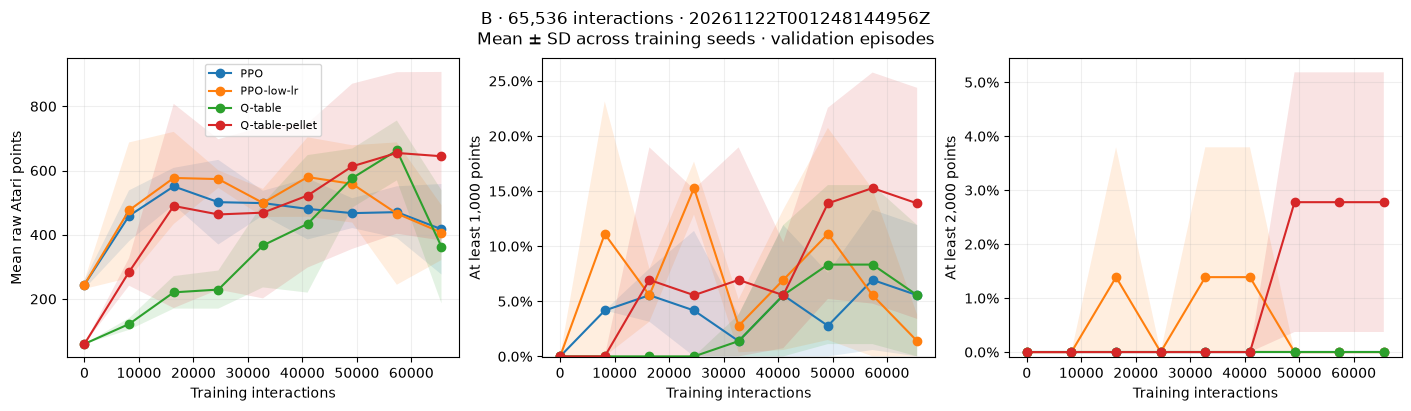

In [9]:
final_results = report(full_stage)

## Evaluer et lagret målepunkt

Sett EVAL_CHECKPOINT til for eksempel 32_768 dersom du vil sammenligne to budsjetter med de samme testfrøene. Velg blant målepunktene fra monitoreringen. Dette starter ingen ny trening.

In [ ]:
EVAL_CHECKPOINT = None  # for example 32_768
if EVAL_CHECKPOINT is not None:
    selected_stage = earlier_stage(full_stage, EVAL_CHECKPOINT)
    selected_results = report(selected_stage, reference=dict(budget=full_stage["budget"], agents=final_results))

: 